RUL true:        1500 cycles
RUL mean:        1375.7 cycles
RUL 5th perc:    950.0 cycles
RUL 95th perc:   1850.0 cycles
Coverage factor: 67.5 %
MRAE:            0.1597
RMSE:            297.8 cycles


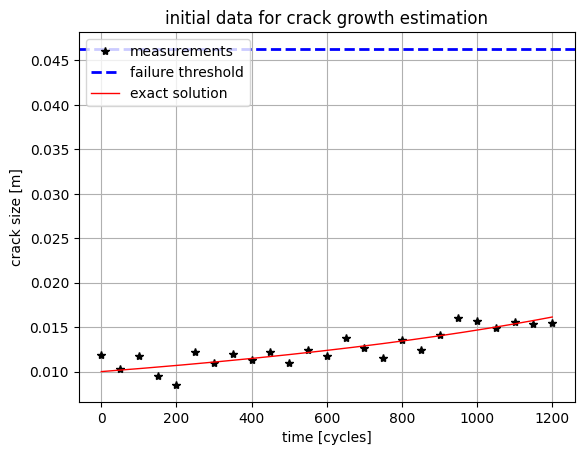

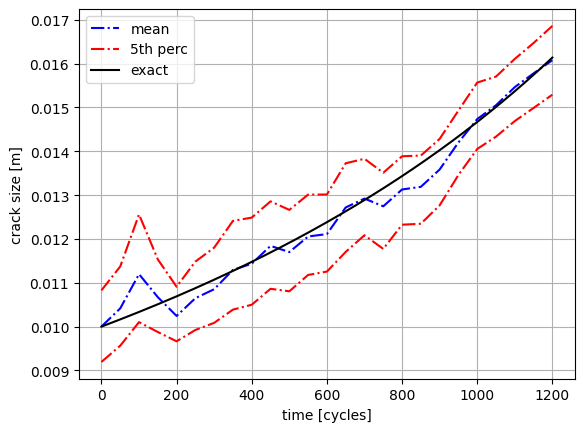

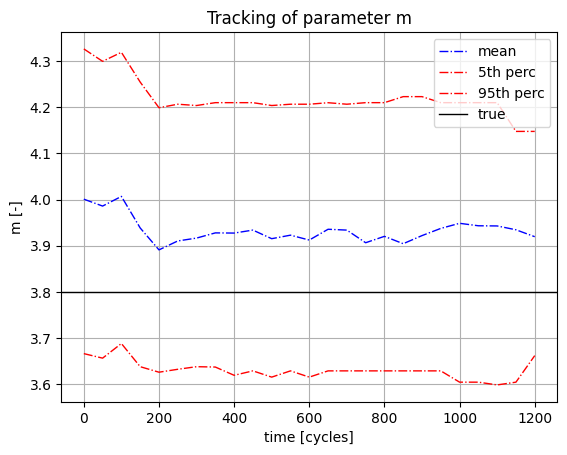

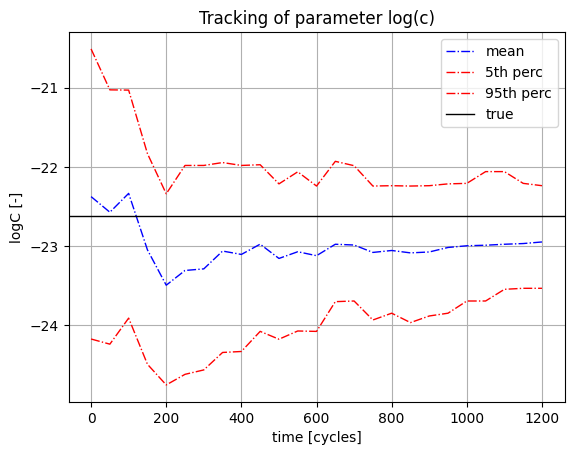

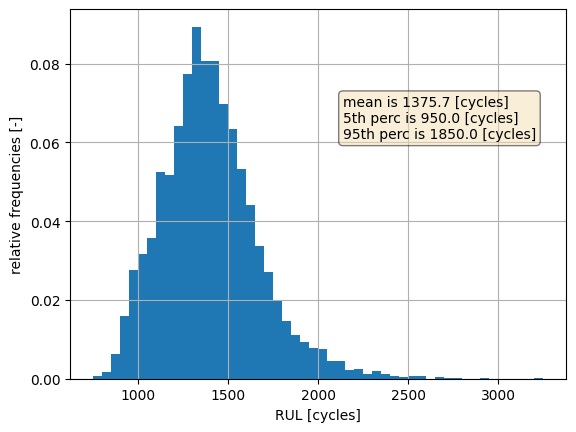

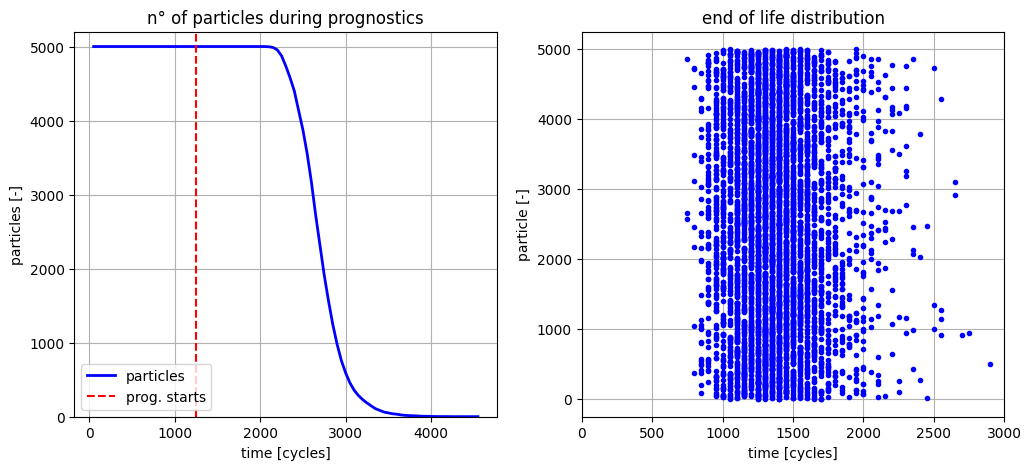

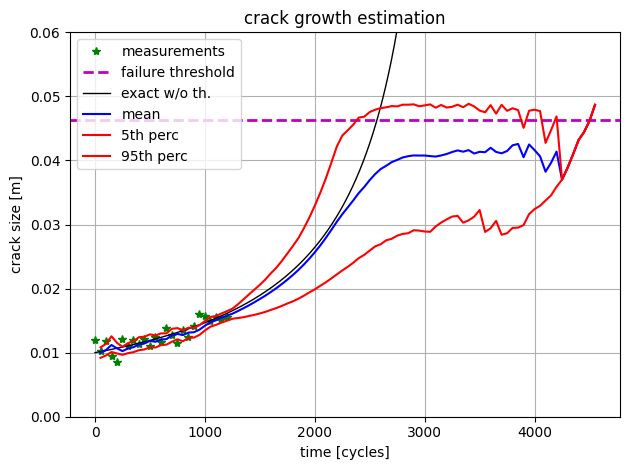

In [ ]:
"""
ARTIFICIAL INTELLIGENCE AND ADVANCED SIMULATION FOR THE SAFETY, RELIABILITY AND MAINTENANCE OF ENERGY SYSTEMS
PROJECT WORK - CRACK GROWTH PROGNOSTICS WITH PARTICLE FILTERING TECHNIQUE
FRANCESCO GALEAZZI
"""

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# =============================================================================
# DATA
# =============================================================================
measured_data = np.array([0.0119, 0.0103, 0.0118, 0.0095, 0.0085, 0.0122, 0.0110,
                           0.0120, 0.0113, 0.0122, 0.0110, 0.0124, 0.0117, 0.0138,
                           0.0127, 0.0115, 0.0135, 0.0124, 0.0141, 0.0160, 0.0157,
                           0.0149, 0.0156, 0.0153, 0.0155])

cycles     = 50          # [-]
finalcycle = 24          # [-]
tend       = 1200        # [cycles]
timestep   = np.arange(0, finalcycle + 1)
time       = np.arange(0, tend + 1, cycles, dtype=float)

failure_tr  = 0.0463     # [m]
m_true      = 3.8        # [-]
c_true      = 1.5e-10    # [-]
delta_sigma = 78         # [MPa]

# =============================================================================
# EXACT ODE SOLUTION
# =============================================================================
a0 = 0.01
odefun = lambda N, a: c_true * (delta_sigma * np.sqrt(np.pi * a)) ** m_true
sol = solve_ivp(odefun, [0, tend], [a0], dense_output=True, max_step=1.0)
Nsol = sol.t
asol = sol.y[0]

# =============================================================================
# FIGURE 1 - Initial data
# =============================================================================
fig1, ax1 = plt.subplots()
ax1.plot(time, measured_data, 'k*', linewidth=1, label='measurements')
ax1.axhline(failure_tr, color='b', linestyle='--', linewidth=2, label='failure threshold')
ax1.plot(Nsol, asol, 'r', linewidth=1, label='exact solution')
ax1.set_xlabel('time [cycles]')
ax1.set_ylabel('crack size [m]')
ax1.legend(loc='upper left')
ax1.set_title('initial data for crack growth estimation')
ax1.grid(True)

# =============================================================================
# PARTICLE FILTER SETUP
# =============================================================================
Nsample      = 5000
std_dev_meas = 0.001

# id rows: [mean, std] for [a0, m, logC, sigma_meas]
id_params = np.array([
    [0.01,         5e-4],
    [4.0,          0.2 ],
    [-22.33,       1.12],
    [std_dev_meas, 0.0 ]
])

l = finalcycle + 1  # number of timesteps

# pre-allocation
W    = np.zeros((l, Nsample))
X    = np.zeros((l, Nsample))
M    = np.zeros((l, Nsample))
logC = np.zeros((l, Nsample))
S    = np.zeros((l, Nsample))
llh  = np.zeros((l, Nsample))

Xmean    = np.zeros(l)
X5th     = np.zeros(l)
X95th    = np.zeros(l)
Mmean    = np.zeros(l)
M5th     = np.zeros(l)
M95th    = np.zeros(l)
logCmean = np.zeros(l)
logC5th  = np.zeros(l)
logC95th = np.zeros(l)

# =============================================================================
# INITIALIZATION
# =============================================================================
W[0, :]    = np.ones(Nsample) / Nsample
X[0, :]    = np.random.normal(id_params[0, 0], id_params[0, 1], Nsample)
M[0, :]    = np.random.normal(id_params[1, 0], id_params[1, 1], Nsample)
logC[0, :] = np.random.normal(id_params[2, 0], id_params[2, 1], Nsample)
S[:, :]    = np.random.normal(id_params[3, 0], id_params[3, 1], (l, Nsample))

def weighted_percentile(values, weights, perc):
    """Compute weighted percentile via sorted cumulative weights."""
    idx    = np.argsort(values)
    vs     = values[idx]
    ws     = weights[idx]
    wcum   = np.cumsum(ws)
    i_perc = np.searchsorted(wcum, perc)
    i_perc = min(i_perc, len(vs) - 1)
    return vs[i_perc]

# t=0 statistics
Xmean[0]    = W[0] @ X[0]
X5th[0]     = weighted_percentile(X[0],    W[0], 0.05)
X95th[0]    = weighted_percentile(X[0],    W[0], 0.95)
Mmean[0]    = W[0] @ M[0]
M5th[0]     = weighted_percentile(M[0],    W[0], 0.05)
M95th[0]    = weighted_percentile(M[0],    W[0], 0.95)
logCmean[0] = W[0] @ logC[0]
logC5th[0]  = weighted_percentile(logC[0], W[0], 0.05)
logC95th[0] = weighted_percentile(logC[0], W[0], 0.95)

# =============================================================================
# PARTICLE FILTER LOOP
# =============================================================================
for t in range(1, l):
    # state propagation
    X[t, :] = (np.exp(logC[t-1, :]) *
                (delta_sigma * np.sqrt(np.pi * X[t-1, :])) ** M[t-1, :] *
                cycles + X[t-1, :])

    # likelihood (lognormal)
    zeta      = np.sqrt(np.log(1 + (S[t-1, :] / X[t, :]) ** 2))
    lam       = np.log(X[t, :]) - 0.5 * zeta ** 2
    llh[t, :] = (1.0 / (measured_data[t] * zeta * np.sqrt(2 * np.pi)) *
                 np.exp(-0.5 * ((np.log(measured_data[t]) - lam) / zeta) ** 2))

    # weight update and normalization
    W[t, :] = W[t-1, :] * llh[t, :]
    W[t, :] /= W[t, :].sum()

    Xmean[t] = W[t] @ X[t]
    X5th[t]  = weighted_percentile(X[t], W[t], 0.05)
    X95th[t] = weighted_percentile(X[t], W[t], 0.95)

    # resampling (inverse CDF)
    r       = np.random.rand(Nsample)
    wcum    = np.cumsum(W[t, :])
    ind_res = np.searchsorted(wcum, r)
    ind_res = np.clip(ind_res, 0, Nsample - 1)

    X[t, :]    = X[t, ind_res]
    M[t, :]    = M[t-1, ind_res]
    logC[t, :] = logC[t-1, ind_res]
    W[t, :]    = np.ones(Nsample) / Nsample

    # parameter M statistics
    Mmean[t]    = W[t] @ M[t]
    M5th[t]     = weighted_percentile(M[t],    W[t], 0.05)
    M95th[t]    = weighted_percentile(M[t],    W[t], 0.95)

    # parameter logC statistics
    logCmean[t] = W[t] @ logC[t]
    logC5th[t]  = weighted_percentile(logC[t], W[t], 0.05)
    logC95th[t] = weighted_percentile(logC[t], W[t], 0.95)

# =============================================================================
# FIGURE 2 - State tracking
# =============================================================================
fig2, ax2 = plt.subplots()
ax2.plot(time, Xmean, 'b-.', linewidth=1.5, label='mean')
ax2.plot(time, X5th,  'r-.', linewidth=1.5, label='5th perc')
ax2.plot(time, X95th, 'r-.', linewidth=1.5)
ax2.plot(Nsol, asol,  'k',   linewidth=1.5, label='exact')
ax2.set_xlabel('time [cycles]')
ax2.set_ylabel('crack size [m]')
ax2.legend(loc='best')
ax2.grid(True)

# =============================================================================
# FIGURE 3 - Parameter m tracking
# =============================================================================
fig3, ax3 = plt.subplots()
ax3.plot(time, Mmean, 'b-.', linewidth=1, label='mean')
ax3.plot(time, M5th,  'r-.', linewidth=1, label='5th perc')
ax3.plot(time, M95th, 'r-.', linewidth=1, label='95th perc')
ax3.axhline(m_true, color='k', linewidth=1, label='true')
ax3.set_xlabel('time [cycles]')
ax3.set_ylabel('m [-]')
ax3.legend(loc='best')
ax3.set_title('Tracking of parameter m')
ax3.grid(True)

# =============================================================================
# FIGURE 4 - Parameter logC tracking
# =============================================================================
fig4, ax4 = plt.subplots()
ax4.plot(time, logCmean, 'b-.', linewidth=1, label='mean')
ax4.plot(time, logC5th,  'r-.', linewidth=1, label='5th perc')
ax4.plot(time, logC95th, 'r-.', linewidth=1, label='95th perc')
ax4.axhline(np.log(c_true), color='k', linewidth=1, label='true')
ax4.set_xlabel('time [cycles]')
ax4.set_ylabel('logC [-]')
ax4.legend(loc='best')
ax4.set_title('Tracking of parameter log(c)')
ax4.grid(True)

# =============================================================================
# PROGNOSTICS - RUL prediction
# =============================================================================
w_pred    = W[l-1, :].copy()
m_pred    = M[l-1, :].copy()
logC_pred = logC[l-1, :].copy()

x_mean_id_p = np.mean(X[l-1, :])
x_var_id_p  = np.sum(w_pred * (X[l-1, :] - x_mean_id_p) ** 2)
x_std_id_p  = np.sqrt(x_var_id_p)

# expand X to accommodate prognostics rows (dynamic growth)
X_prog = X.tolist()   # list of rows for dynamic extension
RUL    = np.zeros(Nsample)
T      = np.full(Nsample, l, dtype=int)

for i in range(Nsample):
    while True:
        row = T[i]
        # extend X_prog if needed
        while len(X_prog) <= row:
            X_prog.append(np.zeros(Nsample))
        if X_prog[row][i] == 0:
            xtemp = X_prog[row - 1][i] + np.random.randn() * x_std_id_p
            X_prog[row][i] = (np.exp(logC_pred[i]) *
                               (delta_sigma * np.sqrt(np.pi * xtemp)) ** m_pred[i] *
                               cycles + xtemp)
        if X_prog[row][i] >= failure_tr:
            break
        T[i] += 1

    RUL[i] = (T[i] - l) * cycles

X_full = np.array(X_prog)   # shape: (t_sim, Nsample)
t_sim  = X_full.shape[0]

# RUL statistics
RUL_mean = np.mean(RUL)
RUL5th   = weighted_percentile(RUL, w_pred, 0.05)
RUL95th  = weighted_percentile(RUL, w_pred, 0.95)
RUL_var  = np.sum(w_pred * (RUL - RUL_mean) ** 2)
RUL_std  = np.sqrt(RUL_var)

# =============================================================================
# FIGURE 5 - RUL histogram
# =============================================================================
fig5, ax5 = plt.subplots()
ax5.hist(RUL, bins=50, density=False, weights=np.ones(Nsample)/Nsample)
ax5.set_xlabel('RUL [cycles]')
ax5.set_ylabel('relative frequencies [-]')
ax5.grid(True)
txt = (f"mean is {RUL_mean:.1f} [cycles]\n"
       f"5th perc is {RUL5th:.1f} [cycles]\n"
       f"95th perc is {RUL95th:.1f} [cycles]")
ax5.text(0.55, 0.65, txt, transform=ax5.transAxes,
         bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

# =============================================================================
# EFFECTIVE PARTICLES DURING PROGNOSTICS
# =============================================================================
eff_particles = np.full(t_sim, Nsample)
for i in range(l, t_sim):
    eff_particles[i] = np.sum(X_full[i, :] != 0)

sim_cycles = np.arange(1, t_sim + 1) * cycles

# =============================================================================
# FIGURE 6 - Particles and EOL distribution
# =============================================================================
fig6, (ax6a, ax6b) = plt.subplots(1, 2, figsize=(12, 5))
ax6a.plot(sim_cycles, eff_particles, 'b', linewidth=2)
ax6a.axvline(l * cycles, color='r', linestyle='--', linewidth=1.5)
ax6a.set_xlabel('time [cycles]')
ax6a.set_ylabel('particles [-]')
ax6a.set_ylim([0, 5200])
ax6a.legend(['particles', 'prog. starts'], loc='lower left')
ax6a.set_title('n° of particles during prognostics')
ax6a.grid(True)

ax6b.plot((T - l) * cycles, np.arange(1, Nsample + 1), 'b.')
ax6b.set_xlabel('time [cycles]')
ax6b.set_ylabel('particle [-]')
ax6b.set_xlim([0, 3000])
ax6b.set_title('end of life distribution')
ax6b.grid(True)

# =============================================================================
# STATE EVOLUTION DURING PROGNOSTICS
# =============================================================================
Xmean_full = np.zeros(t_sim)
X5th_full  = np.zeros(t_sim)
X95th_full = np.zeros(t_sim)

Xmean_full[:l] = Xmean
X5th_full[:l]  = X5th
X95th_full[:l] = X95th

for i in range(l, t_sim):
    red      = int(eff_particles[i])
    mask     = X_full[i, :] != 0
    xred     = X_full[i, mask]
    wred     = np.ones(red) / red
    Xmean_full[i] = wred @ xred
    X5th_full[i]  = weighted_percentile(xred, wred, 0.05)
    X95th_full[i] = weighted_percentile(xred, wred, 0.95)

# exact solution for extended timeframe
t_end_exact = tend + 1600
sol_end = solve_ivp(odefun, [0, t_end_exact], [a0], dense_output=True, max_step=1.0)
Nsol_end = sol_end.t
asol_end = sol_end.y[0]

# =============================================================================
# FIGURE 7 - Full prognostics
# =============================================================================
fig7, ax7 = plt.subplots()
ax7.plot(time, measured_data, 'g*', linewidth=1.5, label='measurements')
ax7.axhline(failure_tr, color='m', linestyle='--', linewidth=2, label='failure threshold')
ax7.plot(Nsol_end, asol_end, 'k', linewidth=1, label='exact w/o th.')
ax7.plot(sim_cycles, Xmean_full, 'b', label='mean')
ax7.plot(sim_cycles, X5th_full,  'r', label='5th perc')
ax7.plot(sim_cycles, X95th_full, 'r', label='95th perc')
ax7.set_ylim([0, 0.06])
ax7.set_xlabel('time [cycles]')
ax7.set_ylabel('crack size [m]')
ax7.legend(loc='upper left')
ax7.set_title('crack growth estimation')
ax7.grid(True)

# =============================================================================
# PERFORMANCE INDICATORS
# =============================================================================
# True RUL from exact solution
t_end_conf  = 2600
sol_conf    = solve_ivp(odefun, [tend, t_end_conf], [asol[-1]], dense_output=True, max_step=cycles)
asol_conf   = sol_conf.y[0]
RUL_true    = int(np.sum(asol_conf < failure_tr)) * cycles

# Coverage factor (within mean ± std)
coverage        = np.sum((RUL >= RUL_mean - RUL_std) & (RUL <= RUL_mean + RUL_std))
coverage_factor = 100 * coverage / Nsample

# Mean Relative Absolute Error
mrae = (1 / Nsample) * np.sum(np.abs((RUL_true - RUL) / RUL_true))

# Root Mean Square Error
rmse = np.sqrt((1 / Nsample) * np.sum((RUL - RUL_true) ** 2))

print(f"RUL true:        {RUL_true} cycles")
print(f"RUL mean:        {RUL_mean:.1f} cycles")
print(f"RUL 5th perc:    {RUL5th:.1f} cycles")
print(f"RUL 95th perc:   {RUL95th:.1f} cycles")
print(f"Coverage factor: {coverage_factor:.1f} %")
print(f"MRAE:            {mrae:.4f}")
print(f"RMSE:            {rmse:.1f} cycles")

plt.tight_layout()
plt.show()